## **Comparing the Algorithms**

Apriori, FP-Growth and Eclat return **exactly the same itemsets**; what changes is the **cost**. This notebook puts the three implementations side by side, proves they agree and measures runtime, search space, scalability and the effect of the **data density**.

**Notebooks of this series:** 1. Apriori · 2. FP-Growth · 3. Eclat · 4. Comparing the Algorithms · 5. Association Rules ( Generation, Reduction and Evaluation ) · 6. Interestingness Measures · 7. Sequential Patterns ( SPADE ) · 8. High-Utility Itemsets · 9. Associative Classification ( CBA )

### **0. Environment Setup**

In [1]:
#Import Libs
import sklearn
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler

In [2]:
#Define Colors Palette and Standards for Illustrations
RED, DARK, GRAY, LIGHT, SOFT = "#CD2027", "#404040", "#7F7F7F", "#D9D9D9", "#E9A0A3"

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams.update({
    "figure.figsize": (7.5, 4.2),
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
    "axes.prop_cycle": cycler(color=[RED, DARK, SOFT, GRAY]),
})
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)

### **1. Association Rule Mining**

Finds **items that occur together** (market-basket analysis) in two steps:

1. **Frequent itemsets:** all sets of items with support ≥ *min_support*
2. **Rules** $A \Rightarrow B$ from those itemsets, filtered by confidence, lift…

| Algorithm | Strategy | Key idea |
|---|---|---|
| **Apriori** | breadth-first, level by level | *a superset of an infrequent set is infrequent* (pruning) |
| **FP-Growth** | divide and conquer | compress the data in an **FP-tree**; no candidate generation |
| **Eclat** | depth-first on **tid-lists** | support = size of the **intersection** of transaction lists |

All three return **exactly the same itemsets** ( checked in notebook *4. Comparing the Algorithms* ).

### **2. Dataset: Simulated Retail Baskets**

6 000 baskets generated from **shopper profiles** (breakfast, party, family dinner, baby, healthy), so that natural associations appear, a mild unexpected one (*diapers ⟶ beer*) and a **loyalty-card bundle** (diapers always come with the baby club card).

In [4]:
#Generate the Transactions ( Shopper Profiles + Random Background Items )
rng = np.random.default_rng(RANDOM_STATE)
profiles = {
    "breakfast":     {"bread": .70, "butter": .50, "jam": .35, "milk": .60, "coffee": .50, "sugar": .30, "eggs": .40, "cereal": .30},
    "party":         {"beer": .60, "chips": .60, "soda": .50, "pizza": .35, "ice": .30, "peanuts": .30},
    "family dinner": {"pasta": .60, "tomato_sauce": .50, "cheese": .40, "chicken": .40, "rice": .40, "beans": .30, "salad": .30, "tomato": .30},
    "baby":          {"diapers": .80, "baby_food": .50, "wipes": .50, "milk": .40, "beer": .25},
    "healthy":       {"salad": .60, "fruit": .70, "yogurt": .50, "fish": .40, "lemon": .30, "water": .60, "tomato": .30},
}
items = sorted({i for p in profiles.values() for i in p} | {"baby_club_card"})

def make_basket():
    chosen = rng.choice(list(profiles), size=1 if rng.random() < 0.75 else 2, replace=False)
    basket = {i for p in chosen for i, prob in profiles[p].items() if rng.random() < prob}
    basket |= {i for i in items if rng.random() < 0.025}                      # random background items
    if "diapers" in basket:
        basket.add("baby_club_card")                                           # loyalty-card bundle (always together)
    return frozenset(basket) if basket else frozenset([str(rng.choice(items))])

transactions = [make_basket() for _ in range(6000)]
print("transactions:", len(transactions), "| distinct items:", len(items), "| mean basket size:", round(np.mean([len(t) for t in transactions]), 2))
for t in transactions[:3]:
    print("  ", sorted(t))

transactions: 6000 | distinct items: 31 | mean basket size: 4.72
   ['beans', 'fruit', 'pasta', 'tomato', 'water']
   ['fruit', 'salad', 'tomato_sauce']
   ['fish', 'fruit', 'salad', 'yogurt']


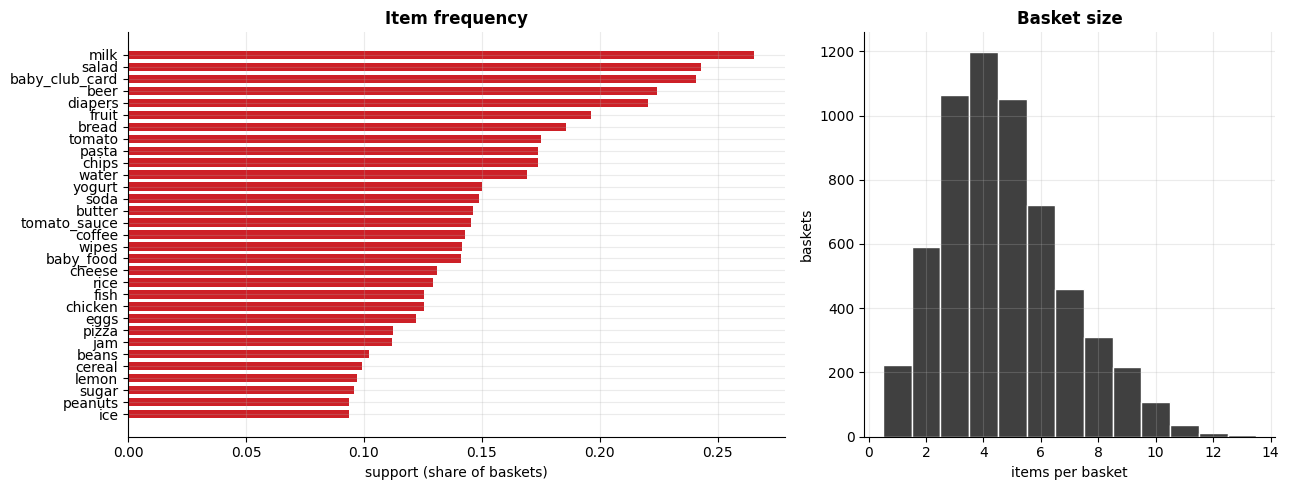

In [5]:
#Explore the Data ( Item Frequency and Basket Size )
freq_items = pd.Series({i: sum(i in t for t in transactions) / len(transactions) for i in items}).sort_values()
sizes = pd.Series([len(t) for t in transactions])

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].barh(freq_items.index, freq_items.values, color=RED, height=0.7); axes[0].set_xlabel("support (share of baskets)"); axes[0].set_title("Item frequency")
axes[1].hist(sizes, bins=range(1, sizes.max() + 2), color=DARK, edgecolor="white", align="left"); axes[1].set_xlabel("items per basket"); axes[1].set_ylabel("baskets"); axes[1].set_title("Basket size")
plt.tight_layout(); plt.show()

### **3. Rule Metrics**

For a rule $A \Rightarrow B$ (all supports are shares of the baskets):

| Metric | Formula | Reading |
|---|---|---|
| **Support** | $P(A \cap B)$ | how frequent |
| **Confidence** | $P(B \mid A)$ | how reliable |
| **Lift** | $\dfrac{P(B \mid A)}{P(B)}$ | $>1$ positive · $=1$ independent · $<1$ negative |
| **Leverage** | $P(A \cap B) - P(A)P(B)$ | excess co-occurrence over independence |
| **Conviction** | $\dfrac{1 - P(B)}{1 - \text{conf}}$ | how much $A$ without $B$ is *unexpected* ($\infty$ if conf = 1) |
| **Zhang's** | $\dfrac{\text{leverage}}{\max\{P(AB)(1-P(A)),\ P(A)(P(B)-P(AB))\}}$ | association from −1 to +1 |

In [6]:
#Bit-Set Representation ( One Integer per Item = Its Transaction List ) and Rule-Metric Function
from itertools import combinations
from collections import Counter, defaultdict
import time

def build_tidsets(transactions):
    tid = defaultdict(int)
    for t_idx, basket in enumerate(transactions):
        bit = 1 << t_idx
        for item in basket:
            tid[item] |= bit
    return dict(tid)

def rule_metrics(s_a, s_b, s_ab):
    conf = s_ab / s_a
    lev = s_ab - s_a * s_b
    denom = max(s_ab * (1 - s_a), s_a * (s_b - s_ab))
    return {"support": s_ab, "confidence": conf, "lift": conf / s_b, "leverage": lev,
            "conviction": (1 - s_b) / (1 - conf) if conf < 1 else np.inf, "zhangs": lev / denom if denom > 0 else 0.0}

tid_all = build_tidsets(transactions)
N = len(transactions)
print("support(beer) =", tid_all["beer"].bit_count() / N, "| support(diapers) =", tid_all["diapers"].bit_count() / N)
for a, b in [("diapers", "beer"), ("diapers", "baby_club_card")]:
    print(f"rule {a} => {b}:", {k: round(v, 3) for k, v in rule_metrics(tid_all[a].bit_count() / N, tid_all[b].bit_count() / N, (tid_all[a] & tid_all[b]).bit_count() / N).items()})

support(beer) = 0.22433333333333333 | support(diapers) = 0.22033333333333333
rule diapers => beer: {'support': 0.066, 'confidence': 0.301, 'lift': 1.342, 'leverage': 0.017, 'conviction': 1.11, 'zhangs': 0.327}
rule diapers => baby_club_card: {'support': 0.22, 'confidence': 1.0, 'lift': 4.152, 'leverage': 0.167, 'conviction': inf, 'zhangs': 0.974}


### **4. Apriori**

Level by level: **join** frequent $(k{-}1)$-itemsets into $k$-candidates, **prune** candidates that have an infrequent subset and **count** the support of the rest.
Counting uses the **bit-set** of each item (support = number of 1-bits of the AND).

In [7]:
#Apriori Implementation ( Join, Prune and Count ) with Statistics per Level
def apriori(tid, n, min_support):
    min_count = int(np.ceil(min_support * n))
    level = {(i,): m for i, m in sorted(tid.items()) if m.bit_count() >= min_count}
    freq = {k: m.bit_count() for k, m in level.items()}
    stats = [{"k": 1, "joined": len(tid), "after pruning": len(tid), "frequent": len(level)}]
    k = 1
    while level:
        keys = sorted(level)
        prev, cands, joined = set(keys), {}, 0
        for a in range(len(keys)):
            for b in range(a + 1, len(keys)):
                if keys[a][:-1] != keys[b][:-1]:
                    break
                joined += 1
                new = keys[a] + (keys[b][-1],)
                if all(sub in prev for sub in combinations(new, k)):                          # prune: every k-subset must be frequent
                    cands[new] = level[keys[a]] & level[keys[b]]
        level = {c: m for c, m in cands.items() if m.bit_count() >= min_count}
        k += 1
        if joined:
            stats.append({"k": k, "joined": joined, "after pruning": len(cands), "frequent": len(level)})
        freq.update({c: m.bit_count() for c, m in level.items()})
    return {frozenset(c): v / n for c, v in freq.items()}, pd.DataFrame(stats)

t0 = time.perf_counter()
freq_apriori, apriori_stats = apriori(tid_all, N, min_support=0.02)
t_apriori = time.perf_counter() - t0
print(f"frequent itemsets (support ≥ 2%): {len(freq_apriori)} | time: {t_apriori:.2f}s")
apriori_stats

frequent itemsets (support ≥ 2%): 326 | time: 0.00s


,k,joined,after pruning,frequent
0,1,31,31,31
1,2,465,465,150
2,3,548,331,124
3,4,129,67,20
4,5,3,2,1


### **5. FP-Growth**

1. Count the items and keep the **frequent** ones, ordered by frequency
2. Insert each basket in an **FP-tree** (shared prefixes share nodes → **compression**)
3. For each item (least frequent first) take its **conditional pattern base**, build a conditional FP-tree and **recurse**

In [9]:
#FP-Growth Implementation ( FP-Tree and Conditional Pattern Bases )
class FPNode:
    __slots__ = ("item", "count", "parent", "children")
    def __init__(self, item, parent):
        self.item, self.count, self.parent, self.children = item, 0, parent, {}

def build_fptree(weighted_paths, min_count):
    counts = defaultdict(int)
    for path, c in weighted_paths:
        for i in path:
            counts[i] += c
    order = {i: r for r, (i, _) in enumerate(sorted(((i, c) for i, c in counts.items() if c >= min_count), key=lambda kv: (-kv[1], kv[0])))}
    root, header, n_nodes = FPNode(None, None), defaultdict(list), 0
    for path, c in weighted_paths:
        node = root
        for i in sorted((i for i in path if i in order), key=order.get):
            child = node.children.get(i)
            if child is None:
                child = FPNode(i, node); node.children[i] = child; header[i].append(child); n_nodes += 1
            child.count += c
            node = child
    return root, header, {i: counts[i] for i in order}, n_nodes

def fp_growth(transactions, min_support):
    n, min_count = len(transactions), int(np.ceil(min_support * len(transactions)))
    root, header, item_counts, n_nodes = build_fptree([(list(t), 1) for t in transactions], min_count)
    result = {}

    def mine(header, item_counts, suffix):
        for item in sorted(item_counts, key=lambda i: (item_counts[i], i)):                  # least frequent first
            new_suffix = suffix | {item}
            result[frozenset(new_suffix)] = sum(nd.count for nd in header[item])
            base = []
            for nd in header[item]:                                                        # conditional pattern base
                path, p = [], nd.parent
                while p.item is not None:
                    path.append(p.item); p = p.parent
                if path:
                    base.append((path, nd.count))
            if base:
                _, h2, counts2, _ = build_fptree(base, min_count)
                if counts2:
                    mine(h2, counts2, new_suffix)

    mine(header, item_counts, frozenset())
    return {k: v / n for k, v in result.items()}, {"tree nodes": n_nodes, "items in baskets": sum(len(t) for t in transactions), "depth": max_depth(root)}

def max_depth(node):
    return 0 if not node.children else 1 + max(max_depth(c) for c in node.children.values())

t0 = time.perf_counter()
freq_fp, fp_info = fp_growth(transactions, min_support=0.02)
t_fp = time.perf_counter() - t0
print(f"frequent itemsets: {len(freq_fp)} | time: {t_fp:.2f}s | FP-tree: {fp_info['tree nodes']} nodes for {fp_info['items in baskets']} item occurrences "
      f"(compression {fp_info['items in baskets'] / fp_info['tree nodes']:.1f}×), depth {fp_info['depth']}")

frequent itemsets: 326 | time: 0.04s | FP-tree: 8081 nodes for 28346 item occurrences (compression 3.5×), depth 13


### **6. Eclat**

Works **vertically**: each item keeps its **tid-list** (here, a bit-set). The support of an extension is the **intersection** of two tid-lists, explored **depth-first** inside *equivalence classes* (itemsets with the same prefix).

In [10]:
#Eclat Implementation ( Depth-First Search on Tid-Lists )
def eclat(tid, n, min_support):
    min_count = int(np.ceil(min_support * n))
    base = sorted(((i, m) for i, m in tid.items() if m.bit_count() >= min_count), key=lambda kv: (kv[1].bit_count(), kv[0]))
    result, counter = {}, {"intersections": 0}

    def recurse(prefix, candidates):
        for idx, (item, m) in enumerate(candidates):
            new_prefix = prefix | {item}
            result[frozenset(new_prefix)] = m.bit_count()
            ext = []
            for item2, m2 in candidates[idx + 1:]:
                nm = m & m2
                counter["intersections"] += 1
                if nm.bit_count() >= min_count:
                    ext.append((item2, nm))
            if ext:
                recurse(new_prefix, ext)

    recurse(frozenset(), base)
    return {k: v / n for k, v in result.items()}, counter

t0 = time.perf_counter()
freq_eclat, eclat_info = eclat(tid_all, N, min_support=0.02)
t_eclat = time.perf_counter() - t0
print(f"frequent itemsets: {len(freq_eclat)} | time: {t_eclat:.2f}s | tid-list intersections: {eclat_info['intersections']}")

frequent itemsets: 326 | time: 0.00s | tid-list intersections: 875


In [10]:
#Cross-Check ( Apriori, FP-Growth and Eclat Return the Same Itemsets and Supports )
same = (set(freq_apriori) == set(freq_fp) == set(freq_eclat)) and all(abs(freq_apriori[k] - freq_fp[k]) < 1e-12 and abs(freq_apriori[k] - freq_eclat[k]) < 1e-12 for k in freq_apriori)
print("Apriori, FP-Growth and Eclat return exactly the same itemsets and supports:", same)

Apriori, FP-Growth and Eclat return exactly the same itemsets and supports: True


### **7. Comparing the Algorithms**

Running time and number of itemsets as the **minimum support** decreases (the lower the threshold, the larger the search space).

,min_support,itemsets,Apriori (s),FP-Growth (s),Eclat (s),FP-tree compression,Eclat intersections
0,0.100,36,0.001,0.024,2.516e-04,4.868,326
1,0.050,104,0.001,0.091,4.267e-04,3.508,515
2,0.030,199,0.002,0.031,7.537e-04,3.508,656
3,0.020,326,0.003,0.037,9.248e-04,3.508,875
4,0.010,806,0.009,0.117,3.016e-03,3.508,3377
5,0.005,2048,0.027,0.135,7.398e-03,3.508,6948
6,0.003,5269,0.041,0.176,1.429e-02,3.508,14641


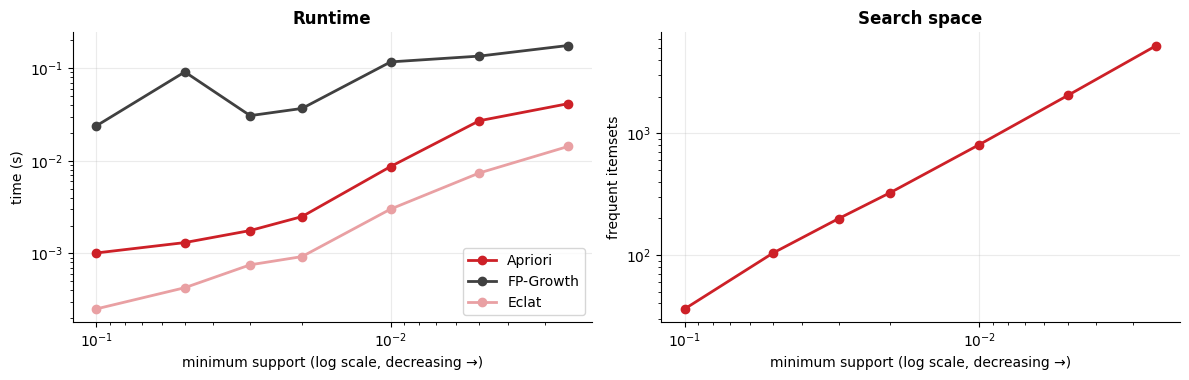

In [11]:
#Runtime and Number of Frequent Itemsets by Minimum Support
rows = []
for ms in [0.10, 0.05, 0.03, 0.02, 0.01, 0.005, 0.0025]:
    t0 = time.perf_counter(); fa, _ = apriori(tid_all, N, ms); ta = time.perf_counter() - t0
    t0 = time.perf_counter(); ff, info = fp_growth(transactions, ms); tf = time.perf_counter() - t0
    t0 = time.perf_counter(); fe, ei = eclat(tid_all, N, ms); te = time.perf_counter() - t0
    assert set(fa) == set(ff) == set(fe)
    rows.append({"min_support": ms, "itemsets": len(fa), "Apriori (s)": ta, "FP-Growth (s)": tf, "Eclat (s)": te,
                 "FP-tree compression": info["items in baskets"] / info["tree nodes"], "Eclat intersections": ei["intersections"]})
bench = pd.DataFrame(rows)
display(bench)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
for col, color in zip(["Apriori (s)", "FP-Growth (s)", "Eclat (s)"], [RED, DARK, SOFT]):
    axes[0].plot(bench["min_support"], bench[col], marker="o", color=color, lw=2, label=col.replace(" (s)", ""))
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].invert_xaxis(); axes[0].set_xlabel("minimum support (log scale, decreasing →)"); axes[0].set_ylabel("time (s)"); axes[0].set_title("Runtime"); axes[0].legend()
axes[1].plot(bench["min_support"], bench["itemsets"], marker="o", color=RED, lw=2); axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].invert_xaxis()
axes[1].set_xlabel("minimum support (log scale, decreasing →)"); axes[1].set_ylabel("frequent itemsets"); axes[1].set_title("Search space")
plt.tight_layout(); plt.show()

In pure Python with bit-sets, Apriori and Eclat have the lowest constant factors here. The advantage of FP-Growth (no candidate generation) grows with **long patterns** and **dense data**.

### **8. Where Each Algorithm Wins**

In [ ]:
#Dense Synthetic Baskets ( Every Item Appears in 90% of the Baskets ) and Dataset Density
def dense_baskets(n=1500, n_items=22, p=0.9, seed=RANDOM_STATE):
    r = np.random.default_rng(seed)
    return [frozenset(i for i in range(n_items) if r.random() < p) or frozenset([0]) for _ in range(n)]

dense = dense_baskets()
t0 = time.perf_counter(); tid_dense = build_tidsets(dense); t_build_dense = time.perf_counter() - t0
pd.DataFrame({"baskets": [len(transactions), len(dense)], "items": [len(items), 22],
              "mean basket size": [np.mean([len(t) for t in transactions]), np.mean([len(t) for t in dense])]},
             index=["retail baskets ( sparse )", "synthetic dense data"]).assign(density=lambda d: d["mean basket size"] / d["items"]).round(3)

In [ ]:
#Runtime on Dense Data by Minimum Support ( All the Algorithms Must Return the Same Itemsets )
# Apriori and Eclat also need the tid-lists, so the time to build them is included in their runtime ( a fair comparison )
rows = []
for ms in [0.8, 0.7, 0.6, 0.5]:
    t0 = time.perf_counter(); fa, _ = apriori(tid_dense, len(dense), ms); ta = time.perf_counter() - t0 + t_build_dense
    t0 = time.perf_counter(); ff, info = fp_growth(dense, ms); tf = time.perf_counter() - t0
    t0 = time.perf_counter(); fe, _ = eclat(tid_dense, len(dense), ms); te = time.perf_counter() - t0 + t_build_dense
    assert set(fa) == set(ff) == set(fe)
    rows.append({"min_support": ms, "itemsets": len(fa), "Apriori (s)": ta, "FP-Growth (s)": tf, "Eclat (s)": te, "Apriori / FP-Growth ( mining only )": (ta - t_build_dense) / tf})
bench_dense = pd.DataFrame(rows)
bench_dense["fastest"] = bench_dense[["Apriori (s)", "FP-Growth (s)", "Eclat (s)"]].idxmin(axis=1).str.replace(" (s)", "", regex=False)
bench_dense.round(3)

In [ ]:
#Scalability: Runtime as the Number of Baskets Grows ( min support 2%, Baskets Replicated, Tid-List Building Included )
rows = []
for k in [1, 2, 4]:
    big = transactions * k
    t0 = time.perf_counter(); tid_big = build_tidsets(big); t_build = time.perf_counter() - t0
    t0 = time.perf_counter(); fa, _ = apriori(tid_big, len(big), 0.02); ta = time.perf_counter() - t0 + t_build
    t0 = time.perf_counter(); ff, _ = fp_growth(big, 0.02); tf = time.perf_counter() - t0
    t0 = time.perf_counter(); fe, _ = eclat(tid_big, len(big), 0.02); te = time.perf_counter() - t0 + t_build
    assert set(fa) == set(ff) == set(fe)
    rows.append({"baskets": len(big), "Apriori (s)": ta, "FP-Growth (s)": tf, "Eclat (s)": te})
scal = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(7, 3.8))
for col, color in zip(["Apriori (s)", "FP-Growth (s)", "Eclat (s)"], [RED, DARK, SOFT]):
    ax.plot(scal["baskets"], scal[col], marker="o", color=color, lw=2, label=col.replace(" (s)", ""))
ax.set_xlabel("baskets"); ax.set_ylabel("time (s)"); ax.set_title("Scalability"); ax.legend()
plt.show()
scal.round(3)

### **9. Summary**

| | **Apriori** | **FP-Growth** | **Eclat** |
|---|---|---|---|
| Strategy | breadth-first, candidates | FP-tree, no candidates | depth-first, tid-list intersections |
| Memory | candidates per level | the FP-tree | tid-lists |
| Database scans | one per level | two | one ( to build the tid-lists ) |
| Specific metrics | candidates, pruning, passes | tree nodes, compression | intersections |
| In practice | `mlxtend.frequent_patterns.apriori` | `mlxtend.frequent_patterns.fpgrowth` | – |

**What the experiments show:** in this pure-Python implementation with bit-sets, Eclat and Apriori are faster in absolute time. The last column of the dense-data table ( *Apriori / FP-Growth*, mining time only ) tends to **rise as the support decreases and the patterns get longer** ( the first rows are too fast to be reliable ), i.e. the gap closes, because the number of candidates explodes while FP-Growth keeps working on the compressed tree. That trend, and not the absolute time of one implementation, is the usual argument for candidate-free methods on dense data or very low supports; the compiled libraries ( e.g. `mlxtend` ) implement them with optimized structures.

When even those become too slow, raise the *min_support* or mine only **closed / maximal** itemsets ( see *5. Association Rules* ).